In [3]:
from google.colab import files
import pandas as pd
uploaded = files.upload()
df = pd.read_csv("Phishing_Detection_Dataset.csv", header=0)

Saving Phishing_Detection_Dataset.csv to Phishing_Detection_Dataset (1).csv


In [ ]:
# Installation des librairies nécessaires
!pip install numpy pandas matplotlib seaborn scikit-learn tensorflow

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (Conv1D, MaxPooling1D, Dense, Flatten,
                                    Dropout, BatchNormalization, LSTM,
                                    Input, concatenate)
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.utils import to_categorical

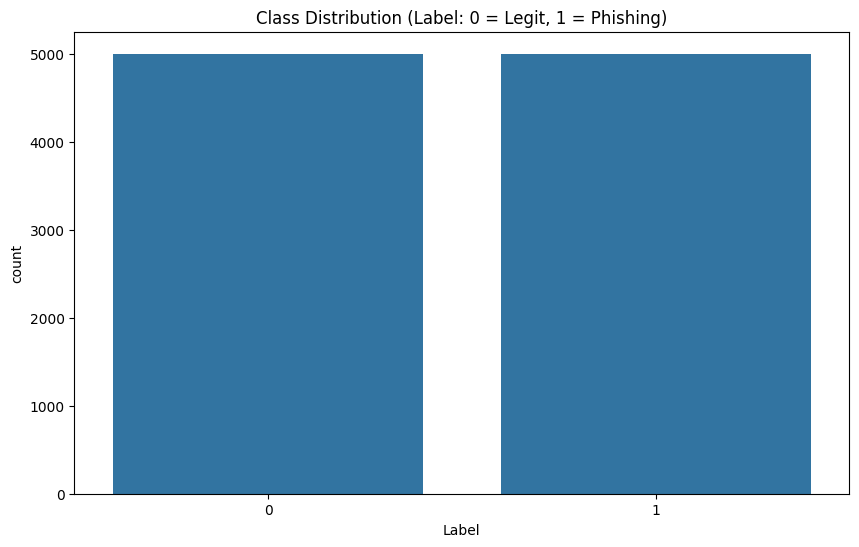

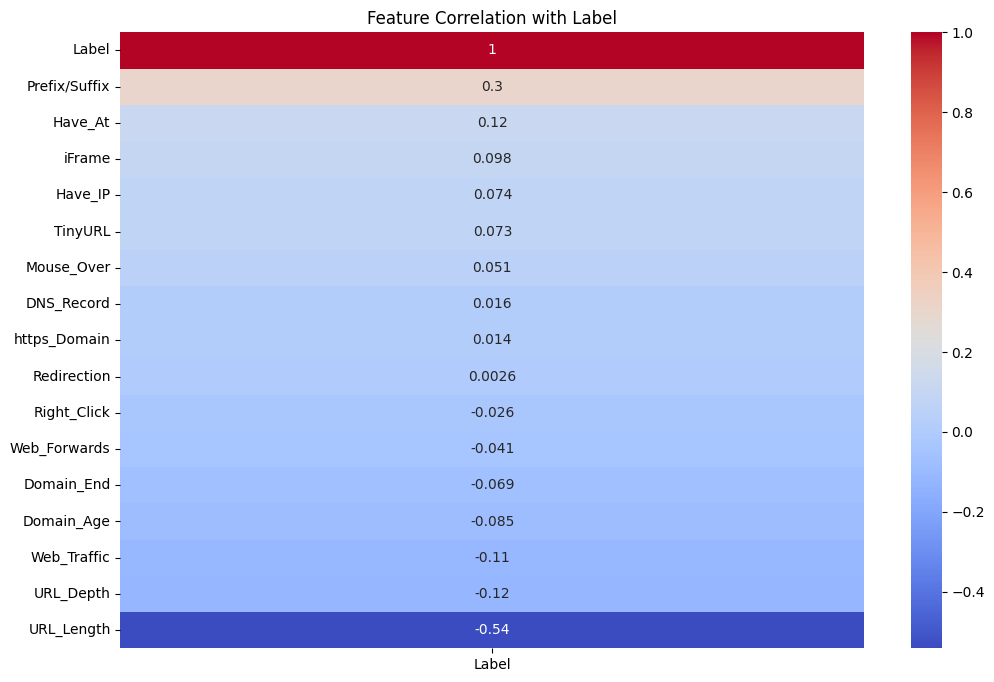

In [ ]:
# ---------------------------------------------------
# Étape 2: Analyse exploratoire (EDA)
# ---------------------------------------------------
plt.figure(figsize=(10, 6))
sns.countplot(x='Label', data=df)
plt.title('Class Distribution (Label: 0 = Legit, 1 = Phishing)')
plt.show()

# Correlation heatmap with Label
plt.figure(figsize=(12, 8))
sns.heatmap(
    df.drop(columns=['Domain']).corr()[['Label']].sort_values('Label', ascending=False),
    annot=True,
    cmap='coolwarm'
)
plt.title('Feature Correlation with Label')
plt.show()


In [ ]:
X = df.drop(columns=['Domain', 'Label']).values
y = df['Label'].astype(int).values 

# Vérification du déséquilibre des classes
print("\nDistribution des classes avant traitement:")
print(f"Classe 0 (Légitime): {np.sum(y == 0)} échantillons")
print(f"Classe 1 (Phishing): {np.sum(y == 1)} échantillons")

# ---------------------------------------------------
# Étape 3: Normalisation et reshaping
# ---------------------------------------------------
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Redimensionnement pour CNN/LSTM (ajout de la dimension canal)
X_3d = X.reshape(X.shape[0], X.shape[1], 1)

# Split train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Version 3D pour les réseaux séquentiels
X_train_3d = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test_3d = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

# Affichage des formes finales
print("\nFormes des données préparées:")
print(f"X_train shape: {X_train.shape}")
print(f"X_train_3d shape: {X_train_3d.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")



Distribution des classes avant traitement:
Classe 0 (Légitime): 5000 échantillons
Classe 1 (Phishing): 5000 échantillons

Formes des données préparées:
X_train shape: (8000, 16)
X_train_3d shape: (8000, 16, 1)
X_test shape: (2000, 16)
y_train shape: (8000,)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 16, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 16, 64)    │        256 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 16, 64)    │        256 │ conv1d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 8, 64)     │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 8, 64)     │          0 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 8, 128)    │     24,704 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 8, 128)    │        512 │ conv1d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 16, 64)    │     16,896 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 4, 128)    │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 16, 64)    │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 4, 128)    │          0 │ max_pooling1d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ (None, 32)        │     12,416 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 512)       │          0 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 32)        │          0 │ lstm_1[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 544)       │          0 │ flatten[0][0],    │
│ (Concatenate)       │                   │            │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │    139,520 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256)       │      1,024 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 256)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │        257 │ dropout_4[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 195,841 (765.00 KB)

 Trainable params: 194,945 (761.50 KB)

 Non-trainable params: 896 (3.50 KB)

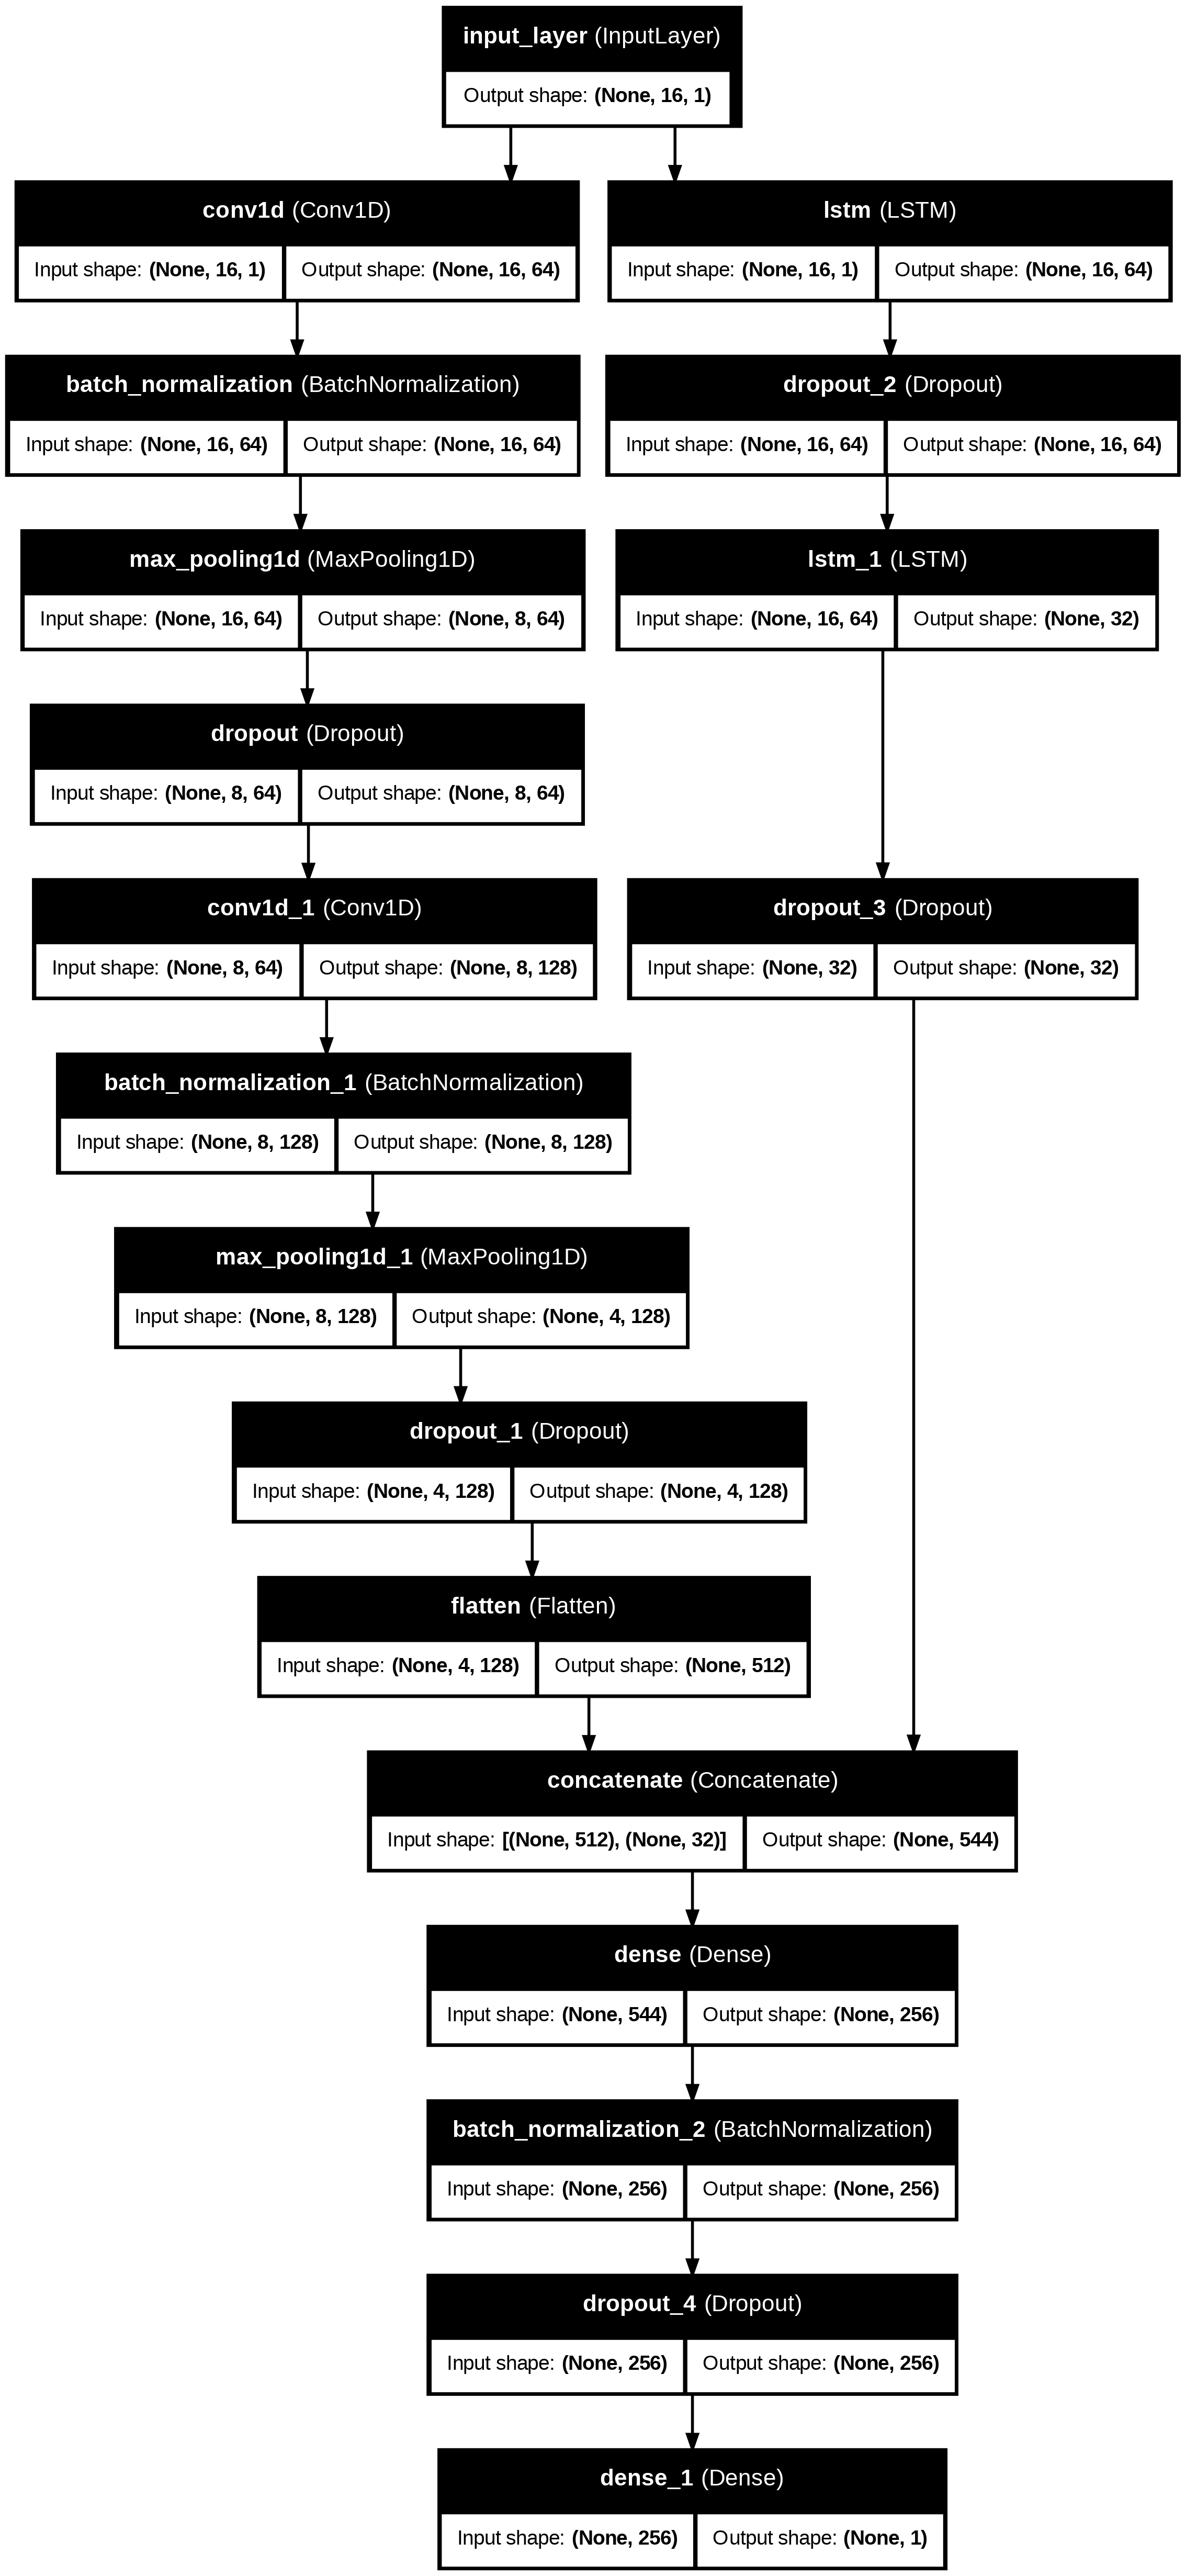

In [ ]:
import tensorflow as tf
from tensorflow.keras.layers import Input, Conv1D, MaxPooling1D, LSTM, Dense, Dropout, BatchNormalization, Flatten, concatenate
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2
from tensorflow.keras.utils import plot_model

# ---------------------------------------------------
# Étape 4: Architecture parallèle CNN-LSTM optimisée
# ---------------------------------------------------
def build_parallel_model(input_shape):
    # Couche d'entrée principale
    input_layer = Input(shape=input_shape)

    # ------------------------
    # Branche CNN optimisée
    # ------------------------
    cnn = Conv1D(64, 3, activation='relu', padding='same',
                 kernel_regularizer=l2(0.01))(input_layer)
    cnn = BatchNormalization()(cnn)
    cnn = MaxPooling1D(2)(cnn)
    cnn = Dropout(0.3)(cnn)

    cnn = Conv1D(128, 3, activation='relu', padding='same',
                 kernel_regularizer=l2(0.01))(cnn)
    cnn = BatchNormalization()(cnn)
    cnn = MaxPooling1D(2)(cnn)
    cnn = Dropout(0.4)(cnn)

    cnn = Flatten()(cnn)

    # ------------------------
    # Branche LSTM optimisée
    # ------------------------
    lstm = LSTM(64, return_sequences=True,
                kernel_regularizer=l2(0.01))(input_layer)
    lstm = Dropout(0.3)(lstm)
    lstm = LSTM(32, kernel_regularizer=l2(0.01))(lstm)
    lstm = Dropout(0.4)(lstm)

    # ------------------------
    # Combinaison des branches
    # ------------------------
    combined = concatenate([cnn, lstm])

    # Couches Dense finales avec régularisation
    combined = Dense(256, activation='relu',
                     kernel_regularizer=l2(0.01))(combined)
    combined = BatchNormalization()(combined)
    combined = Dropout(0.5)(combined)

    output = Dense(1, activation='sigmoid')(combined)

    # Création du modèle
    model = Model(inputs=input_layer, outputs=output)

    # Optimizer avec learning rate adaptatif
    optimizer = Adam(learning_rate=0.001)

    model.compile(optimizer=optimizer,
                  loss='binary_crossentropy',
                  metrics=['accuracy',
                           tf.keras.metrics.Precision(name='precision'),
                           tf.keras.metrics.Recall(name='recall'),
                           tf.keras.metrics.AUC(name='auc')])
    return model

# Construction du modèle
model = build_parallel_model((X_train_3d.shape[1], X_train_3d.shape[2]))

# Affichage du résumé du modèle
model.summary()

# Visualisation de l'architecture du modèle
plot_model(model, to_file='parallel_cnn_lstm.png', show_shapes=True, show_layer_names=True)


Epoch 1/100
 99/100 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.7270 - auc: 0.7823 - loss: 5.0375 - precision: 0.7596 - recall: 0.6617

100/100 ━━━━━━━━━━━━━━━━━━━━ 12s 42ms/step - accuracy: 0.7274 - auc: 0.7827 - loss: 5.0219 - precision: 0.7599 - recall: 0.6622 - val_accuracy: 0.7094 - val_auc: 0.8459 - val_loss: 3.1025 - val_precision: 0.6827 - val_recall: 0.8217
Epoch 2/100
 99/100 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.7736 - auc: 0.8352 - loss: 2.7371 - precision: 0.8035 - recall: 0.7168

100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 62ms/step - accuracy: 0.7737 - auc: 0.8353 - loss: 2.7317 - precision: 0.8036 - recall: 0.7169 - val_accuracy: 0.7594 - val_auc: 0.8488 - val_loss: 2.0606 - val_precision: 0.9206 - val_recall: 0.5867
Epoch 3/100
 99/100 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.7815 - auc: 0.8444 - loss: 1.8412 - precision: 0.8249 - recall: 0.7118

100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.7814 - auc: 0.8443 - loss: 1.8386 - precision: 0.8246 - recall: 0.7118 - val_accuracy: 0.7631 - val_auc: 0.8482 - val_loss: 1.4838 - val_precision: 0.9362 - val_recall: 0.5831
Epoch 4/100
 99/100 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.7999 - auc: 0.8534 - loss: 1.3217 - precision: 0.8584 - recall: 0.7089

100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.7998 - auc: 0.8535 - loss: 1.3200 - precision: 0.8582 - recall: 0.7090 - val_accuracy: 0.7975 - val_auc: 0.8711 - val_loss: 1.0949 - val_precision: 0.9792 - val_recall: 0.6229
Epoch 5/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.7909 - auc: 0.8505 - loss: 1.0343 - precision: 0.8348 - recall: 0.7144

...

100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.8113 - auc: 0.8700 - loss: 0.5472 - precision: 0.8743 - recall: 0.7197 - val_accuracy: 0.8194 - val_auc: 0.8874 - val_loss: 0.4937 - val_precision: 0.9427 - val_recall: 0.6940
Epoch 13/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 6s 38ms/step - accuracy: 0.8135 - auc: 0.8761 - loss: 0.5307 - precision: 0.8693 - recall: 0.7252 - val_accuracy: 0.8144 - val_auc: 0.8806 - val_loss: 0.4962 - val_precision: 0.9210 - val_recall: 0.7024
Epoch 14/100
 99/100 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.8106 - auc: 0.8653 - loss: 0.5443 - precision: 0.8690 - recall: 0.7258

100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.8106 - auc: 0.8654 - loss: 0.5442 - precision: 0.8691 - recall: 0.7258 - val_accuracy: 0.8175 - val_auc: 0.8899 - val_loss: 0.4887 - val_precision: 0.8899 - val_recall: 0.7398
Epoch 15/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.8145 - auc: 0.8762 - loss: 0.5316 - precision: 0.8717 - recall: 0.7265

100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - accuracy: 0.8144 - auc: 0.8762 - loss: 0.5316 - precision: 0.8717 - recall: 0.7265 - val_accuracy: 0.8206 - val_auc: 0.8877 - val_loss: 0.4808 - val_precision: 0.9548 - val_recall: 0.6867
Epoch 16/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 6s 35ms/step - accuracy: 0.8116 - auc: 0.8668 - loss: 0.5441 - precision: 0.8852 - recall: 0.7126 - val_accuracy: 0.8006 - val_auc: 0.8821 - val_loss: 0.5028 - val_precision: 0.8349 - val_recall: 0.7675
Epoch 17/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.8111 - auc: 0.8785 - loss: 0.5246 - precision: 0.8757 - recall: 0.7286

100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - accuracy: 0.8111 - auc: 0.8784 - loss: 0.5246 - precision: 0.8756 - recall: 0.7284 - val_accuracy: 0.8163 - val_auc: 0.8913 - val_loss: 0.4805 - val_precision: 0.9408 - val_recall: 0.6892
Epoch 18/100
 99/100 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.8084 - auc: 0.8613 - loss: 0.5434 - precision: 0.8783 - recall: 0.7133

100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.8085 - auc: 0.8614 - loss: 0.5432 - precision: 0.8784 - recall: 0.7134 - val_accuracy: 0.8256 - val_auc: 0.8904 - val_loss: 0.4740 - val_precision: 0.9480 - val_recall: 0.7024
Epoch 19/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.8113 - auc: 0.8706 - loss: 0.5315 - precision: 0.8841 - recall: 0.7157 - val_accuracy: 0.8200 - val_auc: 0.8890 - val_loss: 0.4783 - val_precision: 0.9221 - val_recall: 0.7133
Epoch 20/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - accuracy: 0.8066 - auc: 0.8650 - loss: 0.5414 - precision: 0.8674 - recall: 0.7093 - val_accuracy: 0.8206 - val_auc: 0.8911 - val_loss: 0.4776 - val_precision: 0.8987 - val_recall: 0.7373
Epoch 21/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 6s 45ms/step - accuracy: 0.8214 - auc: 0.8699 - loss: 0.5243 - precision: 0.8798 - recall: 0.7358 - val_accuracy: 0.8037 - val_auc: 0.8853 - val_loss: 0.4934 - val_precision: 0.8225 - val_recall: 0.7928
Epoch 22/100
100/100 ━━━━━━━━━━━━

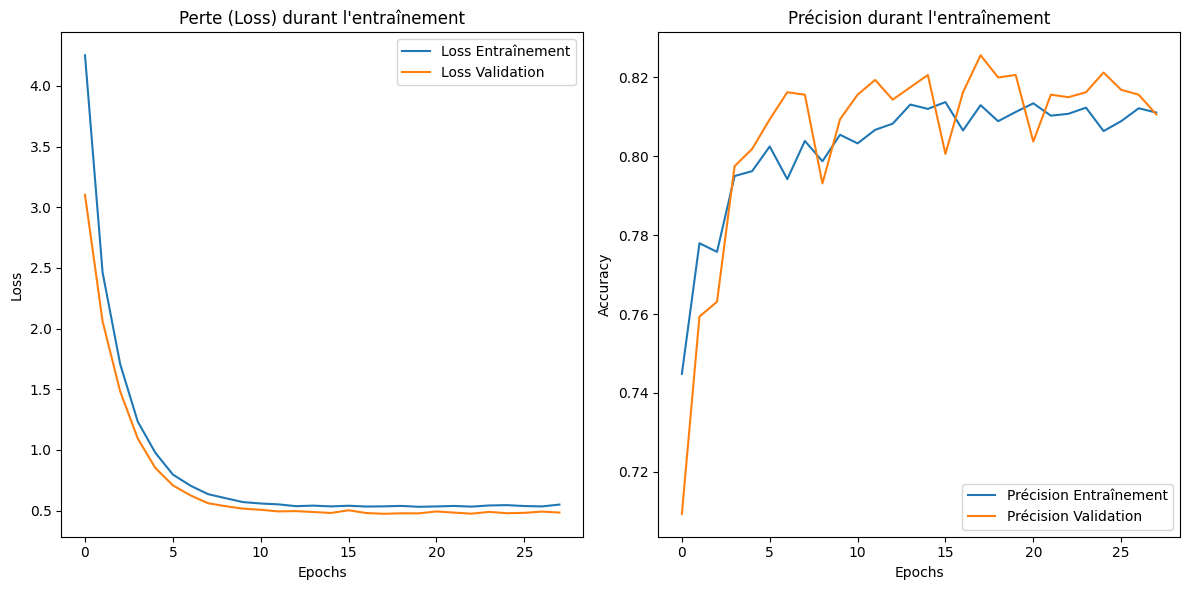

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# ---------------------------------------------------
# Étape 5: Entraînement avec gestion de l'overfitting
# ---------------------------------------------------

# Définir les callbacks pour l'entraînement
callbacks = [
    EarlyStopping(patience=10, restore_best_weights=True),  # Arrêt précoce pour éviter le sur-apprentissage
    ModelCheckpoint('best_parallel_model.h5', save_best_only=True)  # Sauvegarder le meilleur modèle
]

# Entraînement du modèle
history = model.fit(
    X_train_3d,  # Utilisation des données en 3D
    y_train,
    epochs=100,  # Nombre maximal d'époques
    batch_size=64,  # Taille du lot
    validation_split=0.2,  # Fraction des données d'entraînement utilisées pour la validation
    callbacks=callbacks,  # List of callbacks to use
    class_weight={0: 1, 1: 1.2},  # Pondération des classes (en cas de déséquilibre)
    verbose=1  # Affichage du progrès de l'entraînement
)

# Affichage de l'historique de l'entraînement
import matplotlib.pyplot as plt

# Courbes de perte et de précision
plt.figure(figsize=(12, 6))

# Perte d'entraînement et de validation
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Loss Entraînement')
plt.plot(history.history['val_loss'], label='Loss Validation')
plt.title('Perte (Loss) durant l\'entraînement')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# Précision d'entraînement et de validation
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Précision Entraînement')
plt.plot(history.history['val_accuracy'], label='Précision Validation')
plt.title('Précision durant l\'entraînement')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()


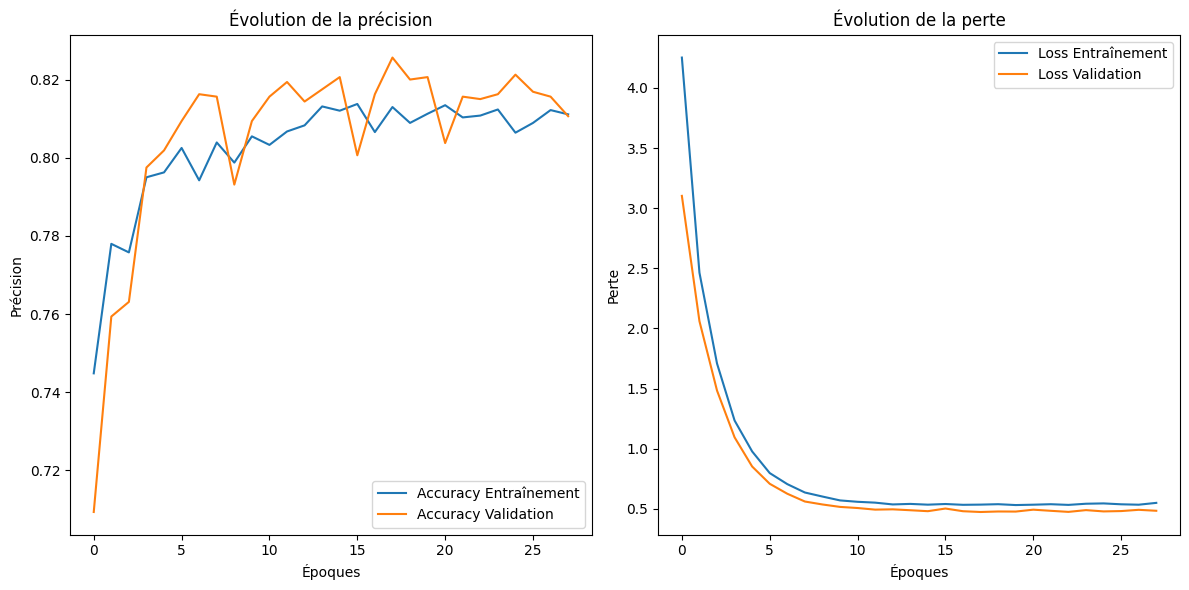

63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step
--- Classification Report ---
              precision    recall  f1-score   support

           0       0.76      0.96      0.85      1000
           1       0.95      0.70      0.80      1000

    accuracy                           0.83      2000
   macro avg       0.85      0.83      0.83      2000
weighted avg       0.85      0.83      0.83      2000



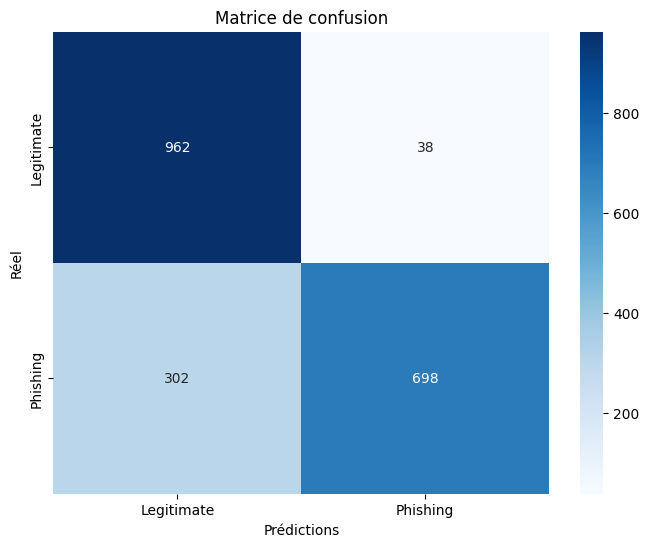

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step


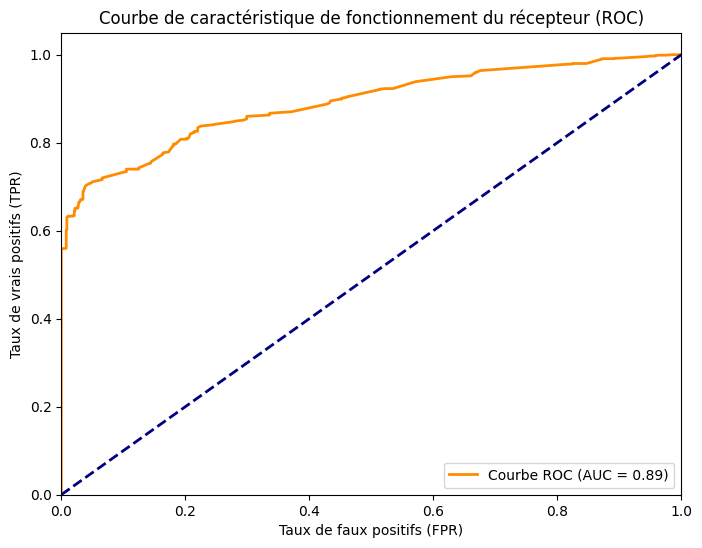

In [ ]:
# ---------------------------------------------------
# Étape 6: Évaluation du modèle
# ---------------------------------------------------

# Visualisation des courbes d'apprentissage
plt.figure(figsize=(12, 6))

# Courbe de précision
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Accuracy Entraînement')
plt.plot(history.history['val_accuracy'], label='Accuracy Validation')
plt.title('Évolution de la précision')
plt.xlabel('Époques')
plt.ylabel('Précision')
plt.legend()

# Courbe de perte
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Loss Entraînement')
plt.plot(history.history['val_loss'], label='Loss Validation')
plt.title('Évolution de la perte')
plt.xlabel('Époques')
plt.ylabel('Perte')
plt.legend()

plt.tight_layout()
plt.show()

# Évaluation finale sur le jeu de test
y_pred = (model.predict(X_test_3d) > 0.5).astype(int)  # Prédiction binaire avec un seuil de 0.5
print("--- Classification Report ---")
print(classification_report(y_test, y_pred))  # Affichage du rapport de classification

# Matrice de confusion
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Legitimate', 'Phishing'], yticklabels=['Legitimate', 'Phishing'])
plt.title('Matrice de confusion')
plt.xlabel('Prédictions')
plt.ylabel('Réel')
plt.show()

# Courbe ROC
fpr, tpr, thresholds = roc_curve(y_test, model.predict(X_test_3d))  # Probabilités pour la courbe ROC
roc_auc = auc(fpr, tpr)

# Visualisation de la courbe ROC
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Courbe ROC (AUC = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taux de faux positifs (FPR)')
plt.ylabel('Taux de vrais positifs (TPR)')
plt.title('Courbe de caractéristique de fonctionnement du récepteur (ROC)')
plt.legend(loc="lower right")
plt.show()


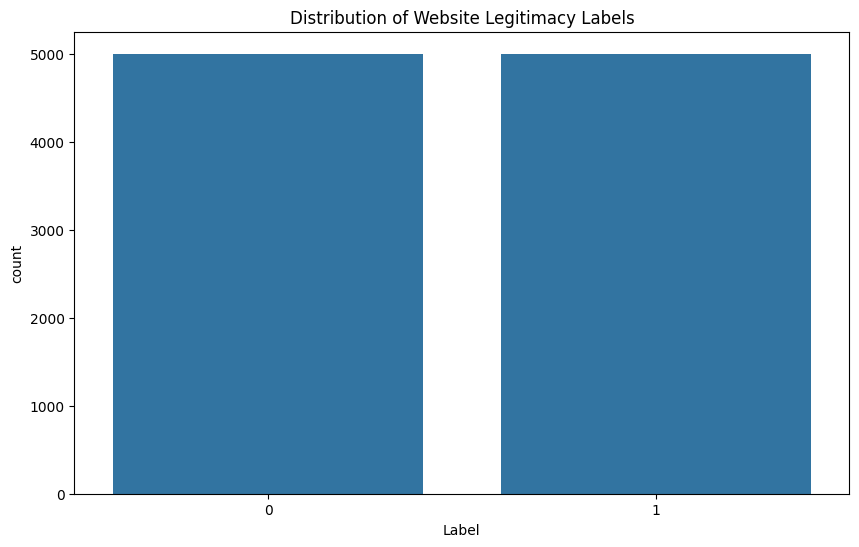

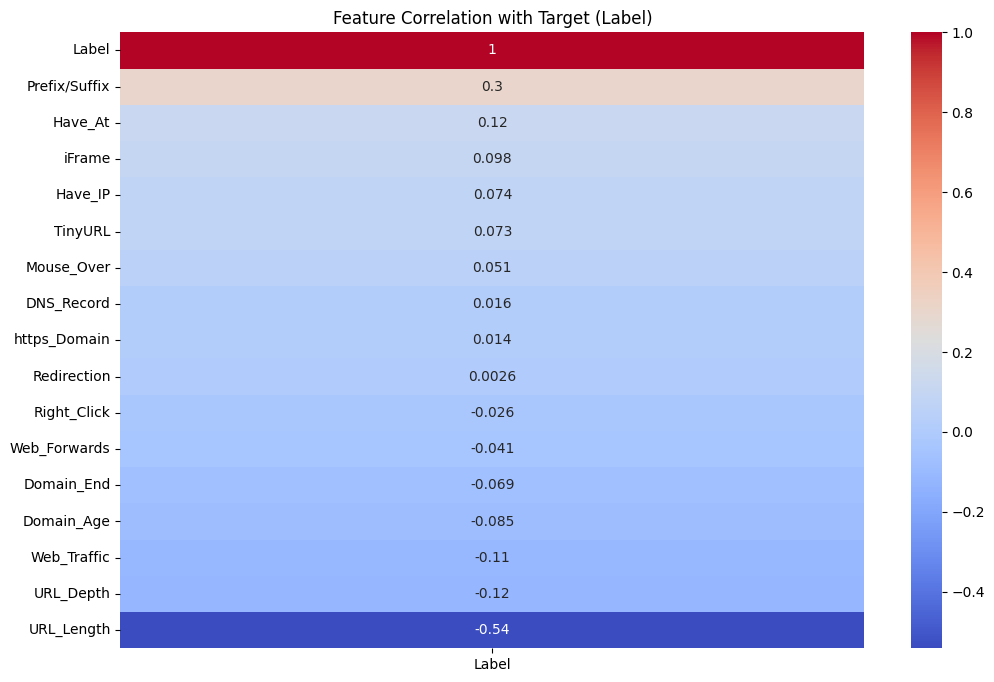

Training MLP model 1/10


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Training MLP model 2/10
Training MLP model 3/10
Training MLP model 4/10


Training MLP model 5/10
Training MLP model 6/10
Training MLP model 7/10
Training MLP model 8/10


Training MLP model 9/10
Training MLP model 10/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.79      0.94      0.86       999
           1       0.93      0.75      0.83       999

    accuracy                           0.85      1998
   macro avg       0.86      0.85      0.85      1998
weighted avg       0.86      0.85      0.85      1998



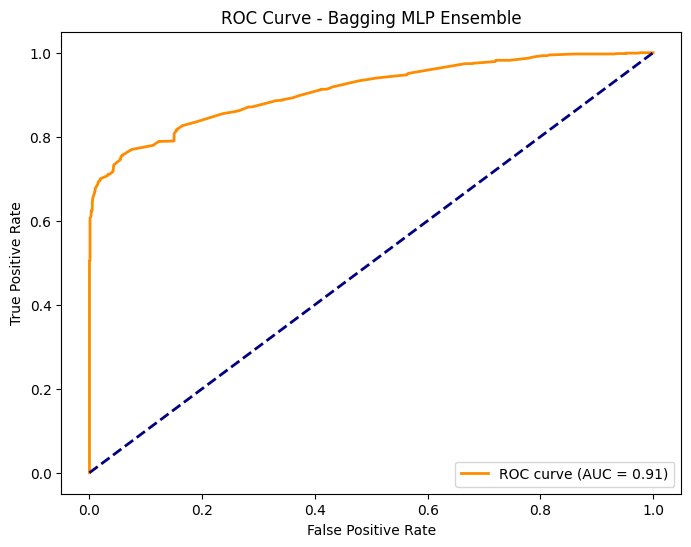

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_curve, auc

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import tensorflow as tf

from sklearn.ensemble import IsolationForest
from imblearn.over_sampling import RandomOverSampler

# ---------------------------
# 1. Preprocess Data
# ---------------------------

# Drop non-numeric or unnecessary columns
df.drop(columns=['Domain'], inplace=True)

# Ensure 'Label' is binary and clean
df.dropna(subset=['Label'], inplace=True)
df['Label'] = df['Label'].astype(int)

# Visualize class distribution
plt.figure(figsize=(10, 6))
sns.countplot(x='Label', data=df)
plt.title('Distribution of Website Legitimacy Labels')
plt.show()

# Visualize correlations
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr()[['Label']].sort_values('Label', ascending=False),
            annot=True, cmap='coolwarm')
plt.title('Feature Correlation with Target (Label)')
plt.show()

# ---------------------------
# 2. Prepare Features & Labels
# ---------------------------
X = df.drop(columns=['Label']).values
y = df['Label'].values

# Normalize features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Anomaly detection
iso = IsolationForest(contamination=0.01, random_state=42)
mask = iso.fit_predict(X) != -1
X, y = X[mask], y[mask]

# Oversample minority class
ros = RandomOverSampler(random_state=42)
X, y = ros.fit_resample(X, y)

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    stratify=y,
                                                    random_state=42)

# ---------------------------
# 3. Define MLP Model
# ---------------------------
def build_mlp(input_shape):
    model = Sequential([
        Dense(128, activation='relu', input_shape=(input_shape,)),
        BatchNormalization(),
        Dropout(0.3),
        Dense(64, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(32, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()])
    return model

# ---------------------------
# 4. Train Bagging Ensemble
# ---------------------------
n_estimators = 10  # Reduced for speed; you can increase this
epochs = 100
batch_size = 64
callbacks = [
    EarlyStopping(patience=10, restore_best_weights=True),
    ModelCheckpoint('best_model.h5', save_best_only=True)
]

bagging_models = []

for i in range(n_estimators):
    print(f"Training MLP model {i+1}/{n_estimators}")
    indices = np.random.choice(len(X_train), size=len(X_train), replace=True)
    X_boot, y_boot = X_train[indices], y_train[indices]
    model = build_mlp(X.shape[1])
    model.fit(X_boot, y_boot,
              epochs=epochs,
              batch_size=batch_size,
              validation_split=0.2,
              callbacks=callbacks,
              class_weight={0: 1, 1: 1.2},
              verbose=0)
    bagging_models.append(model)

# ---------------------------
# 5. Evaluate Ensemble
# ---------------------------
predictions = [model.predict(X_test) for model in bagging_models]
avg_predictions = np.mean(predictions, axis=0)
y_pred = (avg_predictions >= 0.5).astype(int).ravel()

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred))

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, avg_predictions.ravel())
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Bagging MLP Ensemble')
plt.legend(loc='lower right')
plt.show()


   Have_IP  Have_At  URL_Length  URL_Depth  Redirection  https_Domain  \
0        0        0           1          1            0             0   
1        0        0           1          1            1             0   
2        0        0           1          1            0             0   
3        0        0           1          3            0             0   
4        0        0           1          3            0             0   

   TinyURL  Prefix/Suffix  DNS_Record  Web_Traffic  Domain_Age  Domain_End  \
0        0              0           0            1           1           1   
1        0              0           0            1           1           1   
2        0              0           0            1           0           1   
3        0              0           0            1           0           1   
4        0              0           0            1           0           1   

   iFrame  Mouse_Over  Right_Click  Web_Forwards  Label  
0       0           0            1

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



--- Entraînement du modèle MLP 2/8 ---



--- Entraînement du modèle MLP 3/8 ---



--- Entraînement du modèle MLP 4/8 ---



--- Entraînement du modèle MLP 5/8 ---



--- Entraînement du modèle MLP 6/8 ---



--- Entraînement du modèle MLP 7/8 ---



--- Entraînement du modèle MLP 8/8 ---


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step

--- Rapport de classification ---
              precision    recall  f1-score   support

           0       0.79      0.94      0.86       999
           1       0.93      0.76      0.83       999

    accuracy                           0.85      1998
   macro avg       0.86      0.85      0.85      1998
weighted avg       0.86      0.85      0.85      1998



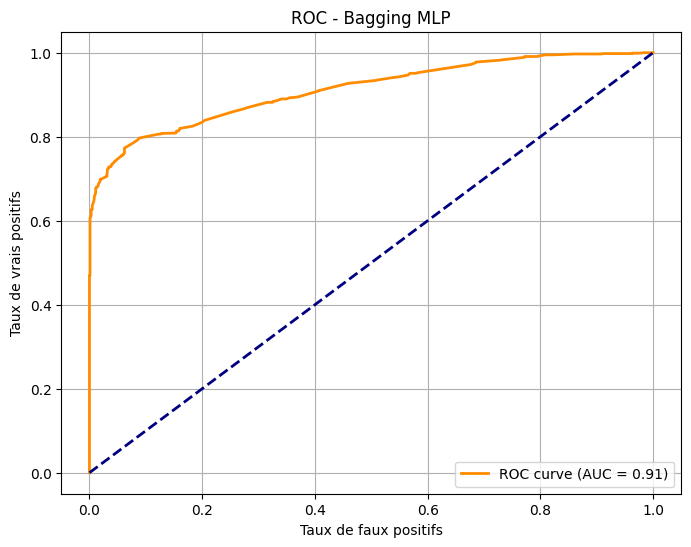

In [ ]:
# Importation des librairies nécessaires
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Prétraitement et Split
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_curve, auc

# Modèles deep learning avec Keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import tensorflow as tf

# Détection des anomalies
from sklearn.ensemble import IsolationForest

# Suréchantillonnage
from imblearn.over_sampling import RandomOverSampler


# Affichage des premières lignes
print(df.head())

# Vérification des colonnes
print("Colonnes :", df.columns)

# Vérification des NaN
df.dropna(subset=['Label'], inplace=True)

# Séparation des features et de la target
X = df.drop(columns=['Label']).values
y = df['Label'].values

# Normalisation
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Suppression des anomalies avec Isolation Forest
iso = IsolationForest(contamination=0.01, random_state=42)
pred_anomalies = iso.fit_predict(X)
mask = pred_anomalies != -1
X = X[mask]
y = y[mask]
print("Après suppression des anomalies :", X.shape)

# Équilibrage des classes
ros = RandomOverSampler(random_state=42)
X, y = ros.fit_resample(X, y)
print("Distribution après équilibrage :", np.bincount(y))

# Split en train/test
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)

# Fonction pour créer un MLP
def build_mlp(input_shape):
    model = Sequential([
        Dense(128, activation='relu', input_shape=(input_shape,)),
        BatchNormalization(),
        Dropout(0.3),
        Dense(64, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(32, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()])
    return model

# Mise en place du bagging
n_estimators = 8
epochs = 100
batch_size = 64
bagging_models = []

# Entraînement de plusieurs MLPs sur des bootstraps
for i in range(n_estimators):
    print(f"\n--- Entraînement du modèle MLP {i+1}/{n_estimators} ---")
    indices = np.random.choice(len(X_train), size=len(X_train), replace=True)
    X_boot, y_boot = X_train[indices], y_train[indices]

    model = build_mlp(X_train.shape[1])
    model.fit(X_boot, y_boot,
              epochs=epochs,
              batch_size=batch_size,
              validation_split=0.2,
              callbacks=[
                  EarlyStopping(patience=10, restore_best_weights=True),
                  ModelCheckpoint(f'best_model_{i}.h5', save_best_only=True)
              ],
              class_weight={0: 1, 1: 1.2},
              verbose=0)
    bagging_models.append(model)

# Agrégation des prédictions
predictions = np.array([model.predict(X_test) for model in bagging_models])
avg_predictions = np.mean(predictions, axis=0)
y_pred = (avg_predictions >= 0.5).astype(int).ravel()

# Évaluation
print("\n--- Rapport de classification ---")
print(classification_report(y_test, y_pred))

# ROC
fpr, tpr, _ = roc_curve(y_test, avg_predictions.ravel())
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (AUC = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('Taux de faux positifs')
plt.ylabel('Taux de vrais positifs')
plt.title('ROC - Bagging MLP')
plt.legend(loc="lower right")
plt.grid()
plt.show()


In [ ]:
# Importation des librairies nécessaires
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Prétraitement et Split
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_curve, auc

# Modèles deep learning avec Keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import tensorflow as tf

# Isolation Forest
from sklearn.ensemble import IsolationForest

# Sur-échantillonnage
from imblearn.over_sampling import RandomOverSampler

# Vérification rapide des colonnes
print("Colonnes :", df.columns)

target_col = 'Label'

# Suppression des lignes avec des valeurs manquantes dans la target
df.dropna(subset=[target_col], inplace=True)

# Séparation des features et de la cible
X = df.drop(columns=[target_col]).values
y = df[target_col].values

# Normalisation
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Suppression des anomalies
iso = IsolationForest(contamination=0.01, random_state=42)
mask = iso.fit_predict(X) != -1
X = X[mask]
y = y[mask]

# Équilibrage
ros = RandomOverSampler(random_state=42)
X, y = ros.fit_resample(X, y)
print("Distribution après équilibrage :", np.bincount(y))

# Split train/test
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)

# Fonction pour construire un MLP
def build_mlp(input_shape):
    model = Sequential([
        Dense(128, activation='relu', input_shape=(input_shape,)),
        BatchNormalization(),
        Dropout(0.3),
        Dense(64, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(32, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()])
    return model

# Bagging avec MLPs
n_estimators = 9
epochs = 100
batch_size = 64
bagging_models = []

# Callbacks
callbacks = [
    EarlyStopping(patience=10, restore_best_weights=True),
    ModelCheckpoint('best_model.h5', save_best_only=True)
]

# Entraînement des MLPs
for i in range(n_estimators):
    print(f"\n--- Entraînement du modèle {i+1}/{n_estimators} ---")
    indices = np.random.choice(len(X_train), size=len(X_train), replace=True)
    X_boot = X_train[indices]
    y_boot = y_train[indices]

    model = build_mlp(X_train.shape[1])
    model.fit(X_boot, y_boot,
              epochs=epochs,
              batch_size=batch_size,
              validation_split=0.2,
              callbacks=callbacks,
              class_weight={0: 1, 1: 1.2},
              verbose=0)
    bagging_models.append(model)

# Prédictions et agrégation
predictions = np.array([model.predict(X_test) for model in bagging_models])
avg_predictions = np.mean(predictions, axis=0)
y_pred_bagging = (avg_predictions >= 0.5).astype(int).ravel()

# Évaluation
print("\n--- Rapport de classification (Bagging - MLP) ---")
print(classification_report(y_test, y_pred_bagging))

# Courbe ROC
fpr, tpr, _ = roc_curve(y_test, avg_predictions.ravel())
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Courbe ROC (AUC = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('Taux de faux positifs')
plt.ylabel('Taux de vrais positifs')
plt.title('Receiver Operating Characteristic - Bagging (MLP)')
plt.legend(loc="lower right")
plt.grid()
plt.show()


Colonnes : Index(['Have_IP', 'Have_At', 'URL_Length', 'URL_Depth', 'Redirection',
       'https_Domain', 'TinyURL', 'Prefix/Suffix', 'DNS_Record', 'Web_Traffic',
       'Domain_Age', 'Domain_End', 'iFrame', 'Mouse_Over', 'Right_Click',
       'Web_Forwards', 'Label'],
      dtype='object')
Distribution après équilibrage : [4995 4995]

--- Entraînement du modèle 1/9 ---


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



--- Entraînement du modèle 2/9 ---



--- Entraînement du modèle 3/9 ---

--- Entraînement du modèle 4/9 ---

--- Entraînement du modèle 5/9 ---

--- Entraînement du modèle 6/9 ---

--- Entraînement du modèle 7/9 ---

--- Entraînement du modèle 8/9 ---

--- Entraînement du modèle 9/9 ---
